# Titanic - Survival prediction

| Variables | Description |
|----------|-----------|
| pclass | {1,2,3}  |
| sex | {male,female} |
| Age | {int, less than 1: 0.x, estimated: xx.5} |
| sibsp | siblings,spouses: {int} |
| parch | parents/children: {int} |
| ticket | Ticket number: {int} |
| fare | Fare: {float} |
| cabin | Cabin: {str} |
|embarked | Embarked: {C,Q,S} |

# 1-Importation des données

*Warning: the architecture should be the same for data to be correctly load !*

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [77]:
import sys
import os
import importlib

sys.path.append(
    os.path.abspath("../src")
)
import Data as pr
importlib.reload(pr)

d = pr.Data()
d.loadData()
d.set_categorial(['Sex','Name','Embarked'])
d.get_categorial()

['Name', 'Sex', 'Embarked']

In [39]:
train = pd.read_csv("../data/train.csv",delimiter= ",",header= 0)
train.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [54]:
x_test = pd.read_csv("../data/test.csv",delimiter= ",",header= 0)
x_test.head(2)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S


# 2- Exploratory Data Analysis

In [43]:
train.drop('Name',axis=1,inplace=True)

In [9]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


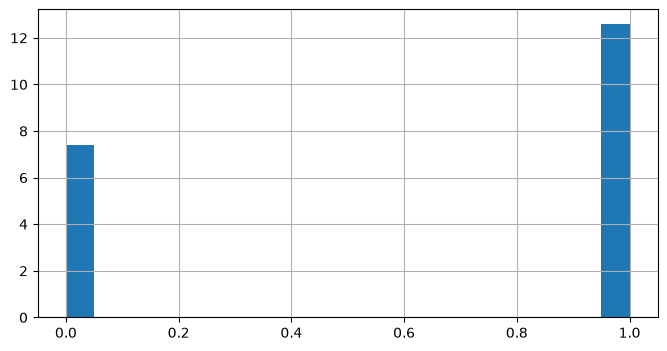

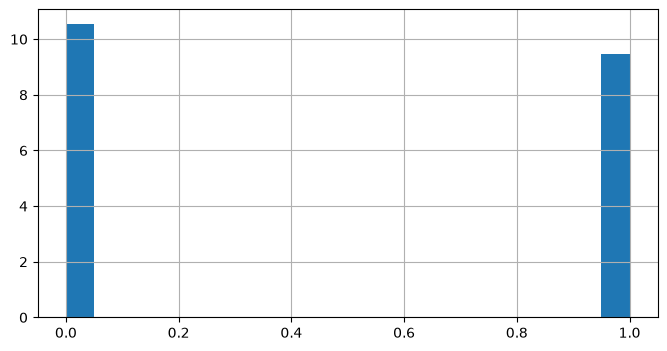

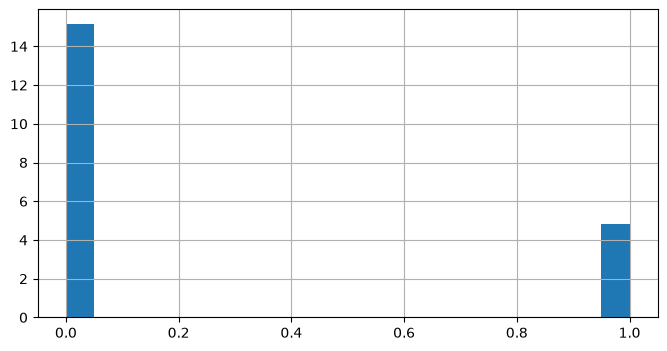

In [10]:
for gare, groupe in train.groupby("Pclass"):
    plt.figure(figsize=(8, 4))
    train.iloc[groupe.index]["Survived"].hist(bins=20, density=True)

# LightGBM

In [40]:
y_train = train["Survived"].copy()
train.drop('Survived',axis=1,inplace=True)
train.drop('Cabin',axis=1,inplace=True)
train.drop('Ticket',axis=1,inplace=True)
train.drop('Embarked',axis=1,inplace=True)
#train["Sex"] = pd.Categorical(train["Sex"]) 
#train["Ticket"] = pd.Categorical(train["Ticket"])
#train["Embarked"] = pd.Categorical(train["Embarked"])  

In [50]:
from sklearn.model_selection import train_test_split

#Découpage du jeu entier en train, validation et test
features_train, features_test, sncf_train, sncf_test = train_test_split(train, y_train, test_size=None, random_state=0)
features_train, features_val, sncf_train, sncf_val = train_test_split(features_train, sncf_train, test_size=0.2, random_state=0)

In [18]:
import optuna
import lightgbm as lgb

In [51]:
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

features_train['Sex'] = features_train['Sex'].map({
    'male': 0,
    'female': 1
})
features_test['Sex'] = features_test['Sex'].map({
    'male': 0,
    'female': 1
})


my_kfold = KFold(n_splits=5, shuffle=True, random_state=0)
tree_range = range(0,100)

tuned_parameters = {'n_estimators': tree_range}

RF = GridSearchCV(RandomForestClassifier(max_features=4),
                       tuned_parameters,
                       cv=my_kfold,
                       n_jobs=-1)

RF.fit(features_train, sncf_train)
#RF.score(features_test,sncf_test)


/home/titou/miniconda3/envs/StaSc/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
5 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/home/titou/miniconda3/envs/StaSc/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/titou/miniconda3/envs/StaSc/lib/python3.14/site-packages/sklearn/base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/home/titou/miniconda3/envs/StaSc/li

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ax_features=4)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': range(0, 100)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information 

In [57]:
"""x_test.drop('Name',axis=1,inplace=True)
x_test.drop('Cabin',axis=1,inplace=True)
x_test.drop('Ticket',axis=1,inplace=True)
x_test.drop('Embarked',axis=1,inplace=True)"""

x_test['Sex'] = x_test['Sex'].map({
    'male': 0,
    'female': 1
})

predictions = RF.predict(x_test)

output = pd.DataFrame({'PassengerId': x_test.PassengerId, 'Survived': predictions})
output.to_csv('submission.csv', index=False)